# Data processing - gate flow cytometry data

# Imports

In [1]:
import os
import pickle
import pandas as pd
import numpy as np
import collections
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.backends.backend_pdf import PdfPages
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from cycler import cycler
import numpy as np
import pylab
import FlowCal
import copy
from matplotlib.lines import Line2D
import warnings
import corner
from matplotlib.colors import ListedColormap

import emcee

# Set default parameters for plots
sns.set_context("talk", font_scale=1, rc={"lines.linewidth": 2.0, 'lines.markersize': 5})
sns.set_style("ticks")
sns.set_style({"xtick.direction": "in","ytick.direction": "in"})
mpl.rc('axes', prop_cycle=(cycler('color', ['r', 'k', 'b','g','y','m','c']) ))
mpl.rc('text', usetex=False)
#mpl.rc('font',**{'family':'sans-serif','sans-serif':['HelveticaNeueThin']})
#plt.tick_params(top=False, bottom=False, right=False, left=False)
tw = 1.5
sns.set_style({"xtick.major.size": 6, "ytick.major.size": 6,
               "xtick.minor.size": 4, "ytick.minor.size": 4,
               'axes.labelsize': 24,
               'xtick.major.width': tw, 'xtick.minor.width': tw,
               'ytick.major.width': tw, 'ytick.minor.width': tw})

mpl.rc('xtick', labelsize=18) 
mpl.rc('ytick', labelsize=18)
mpl.rc('axes', linewidth=1.75)
plt.gcf().subplots_adjust(bottom=0.15)
sns.set_style({'axes.labelsize': 24, 'axes.titlesize': 24})

# %matplotlib inline
# warnings.filterwarnings(action='once')
warnings.filterwarnings('ignore')

<Figure size 640x480 with 0 Axes>

# Functions

In [2]:
# gRNA properties

# This is a new PAM dict that shows the position of the central
# bp of the 33bp dCas9 footprint, which is the 5th bp upstream of PAM.
# Positions are given in absolute values, as in 0 is immediately before +1.
# To convert to genomic position, subtract 1 from all negative values.
PAM_dict = {'g1': -27,
            'g2': -22,
            'g3': -5,
            'g4': 12,
            'g5': 23,
            'g6': 25,
            'g8': 43,
            'g9': 50,
            'g10': 67,
            'g11': 101,
            'g12': 156,
            'g13': 160,
           }

strand_dict = {'g1': 'right',
               'g2': 'left',
               'g3': 'right',
               'g4': 'right',
               'g5': 'left',
               'g6': 'right',
               'g8': 'right',
               'g9': 'left',
               'g10': 'left',
               'g11': 'right',
               'g12': 'right',
               'g13': 'left',
              }

def strand_to_footprint(PAM, strand):
    '''
    PAM is an integer.
    strand is a string that is 'right' or 'left'.
    '''
    if strand == 'right':
        rightwindow = PAM + 8 # 9bp overhang beyond gRNA. N in NGG already included.
        leftwindow = PAM - 20 - 1 #1bp overhang beyond gRNA.
    elif strand == 'left':
        rightwindow = PAM + 20 + 1
        leftwindow = PAM - 8
    else:
        raise('Problem with strand')
    return leftwindow, rightwindow

# D gates

## Replicate 1

### Beads

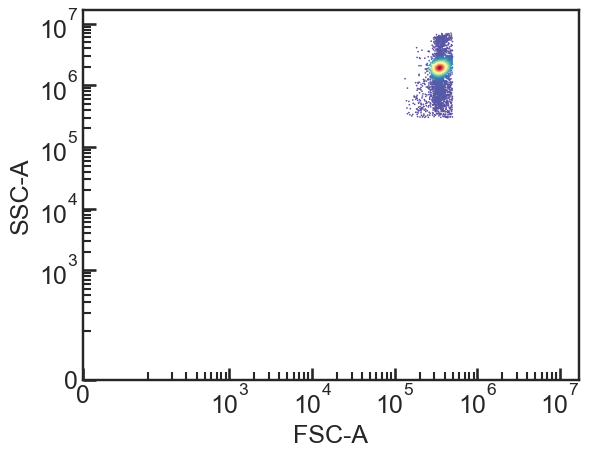

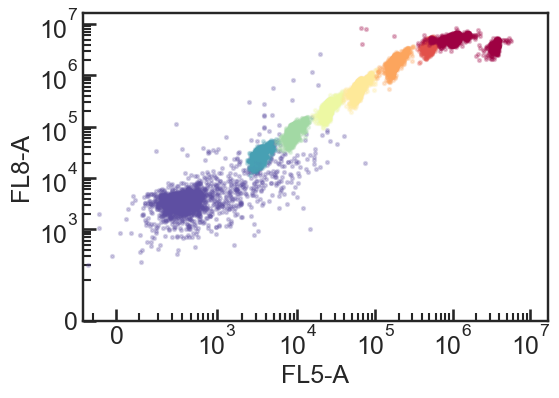

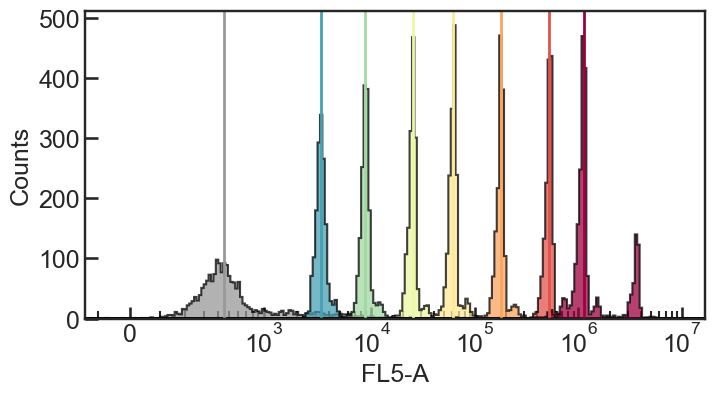

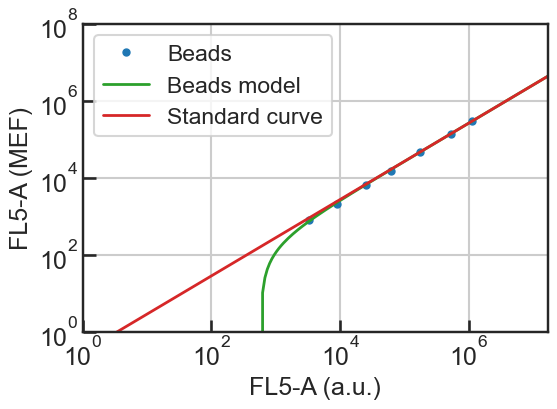

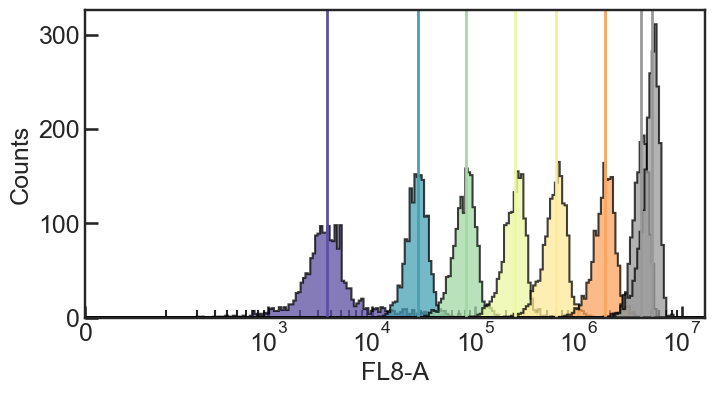

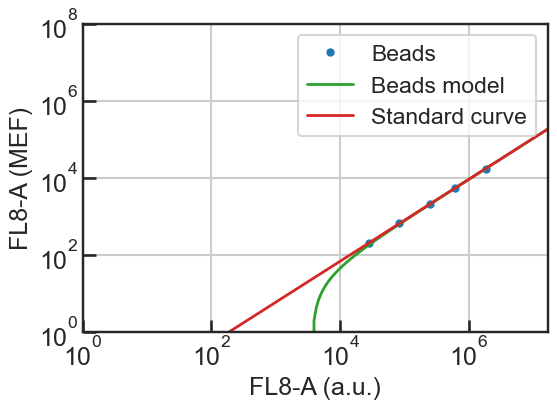

In [8]:
# import FCS data

fileprefix = '../20241130/'

fileext = '.fcs'

m9beads = FlowCal.io.FCSData(fileprefix + '01-Beads-G2' + fileext)

# gate on FSC-A and SSC-A
m9beads_gated = m9beads[(m9beads[:,1] > 1e5) &
                    (m9beads[:,1] < 5e5) &
                    (m9beads[:,3] > 3e5)]
# beads_gated = beads_gated[(beads_gated[:,1] < 8e5) & (beads_gated[:,3] < 3e6)]

FlowCal.plot.density2d(m9beads_gated,
                      channels=['FSC-A','SSC-A'],
                      mode='scatter')

mefl_vals = np.array([0,771,2106,6262,15183,45292,136258,291042])
# meptr_vals = np.array([0,205,643,2021,5278,17018,62451,198933])

# use this because RFP gain is so high that the brightest bead subpopulations overflow.
meptr_vals_low = np.array([0,205,643,2021,5278,17018,np.nan,np.nan]) 

mef_vals = np.array([mefl_vals, meptr_vals_low])

to_mef_m9 = FlowCal.mef.get_transform_fxn(
    m9beads_gated,
    mef_values = mef_vals,
    mef_channels=['FL5-A','FL8-A'],
    plot=True,
)


### FCS files

In [9]:
fcs_dict = dict()

plates = ['04','06','07','08']
rows6 = ['A','B','C','D','E','F']
rows7 = ['A','B','C','D','E','F','G']
grnas6 = ['g1','g2','g3','g4','g5','g6']
grnas7 = ['g8','g9','g10','g11','g12','g13','g14']
cols = [str(i) for i in range(1,13)]

atcs = ['Blank','0','0.02','0.06','0.2','0.43','0.93','2','6','20','60','200']

for plate in plates:
    if (plate=='04') | (plate=='07'):
        rows = rows6
        grnas = grnas6
    else:
        rows = rows7
        if plate == '06':
            grnas = ['g8','g9','g10','g11','g13','g12','g14'] # <- well swap in M9 condition
        else:
            grnas = grnas7
        
    if (plate=='04') | (plate=='06'):
        media = 'M9'
        media_for_key = 'M9'
    else:
        media = 'CLim'
        media_for_key = 'CL'
        
    prefix = plate+'-'+media+'-'
    for r in range(len(rows)):
        for c in range(len(cols)):
            well = rows[r]+cols[c]
            cond = media_for_key+'_'+grnas[r]+'_'+atcs[c]
            
            fcs_dict[cond] = to_mef_m9(FlowCal.transform.to_rfi(FlowCal.io.FCSData(fileprefix + prefix + well + fileext)), channels=['FL5-A','FL8-A'])

        

This replicate's data had additional pruning that needed to be done on the events due to spurious acquisition of debris

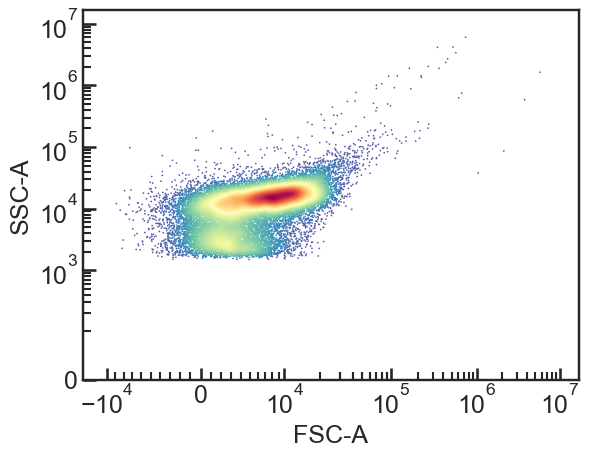

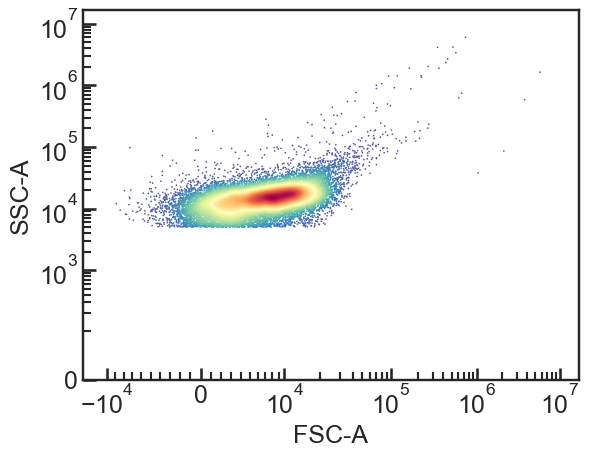

In [11]:
# example FSC/SSC plot to show before/after pruning
fcs = fcs_dict['CL_g14_0.02']

FlowCal.plot.density2d(fcs, channels=['FSC-A', 'SSC-A'], mode='scatter')
plt.show()

cl_ssc_thresh = 5e3
fcs_thresh = fcs[fcs[:,3] > cl_ssc_thresh]

FlowCal.plot.density2d(fcs_thresh, channels=['FSC-A', 'SSC-A'], mode='scatter')
plt.show()

In [12]:
# iterate through all plots and remove sub-threshold events (pruning)

for key in fcs_dict.keys():
    fcs = fcs_dict[key]
    fcs = fcs[fcs[:,3] > cl_ssc_thresh]
    fcs_dict[key] = fcs

### Density gating on FCS data

In [13]:
# This may take a while to run.
frac_to_keep = 0.4

fcs_gated_dict = dict()

for key in fcs_dict.keys():
    fcs = fcs_dict[key]
    
    fcs_gated = FlowCal.gate.density2d(fcs,
                                       channels=['FSC-A','SSC-A'],
                                       gate_fraction=frac_to_keep,
                                      )
    fcs_gated_dict[key] = fcs_gated

### Pickle the gated outputs

In [14]:
# pickle the resulting dictionary

with open('./pickles/241130_fcs_gated_dict.pkl', 'wb') as f:  # open a text file
    pickle.dump(fcs_gated_dict, f) # serialize the list
f.close()

## Replicate 2

### Beads

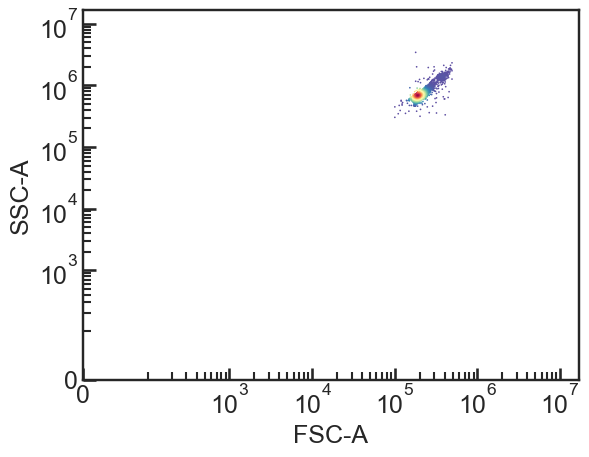

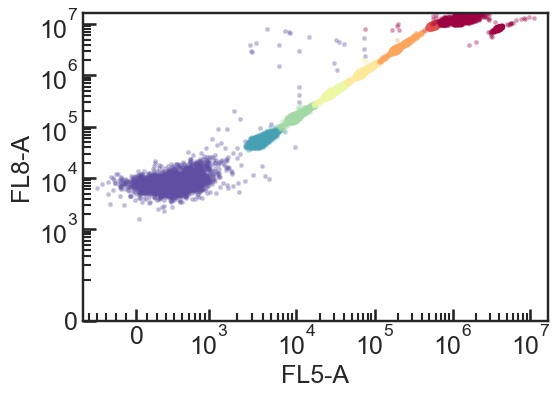

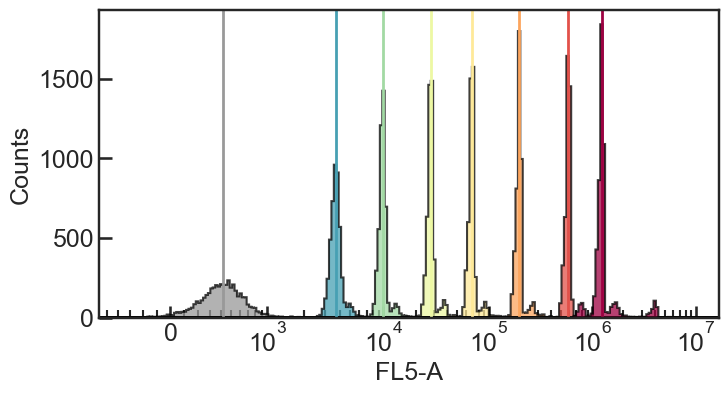

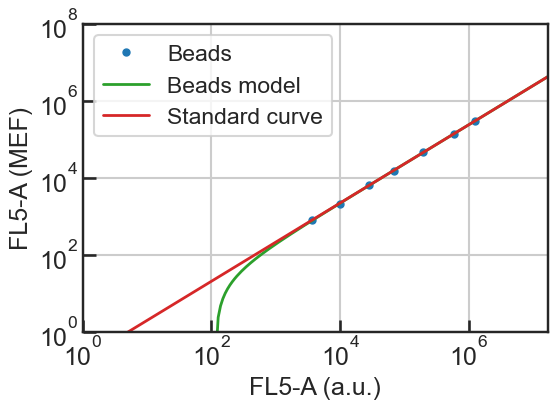

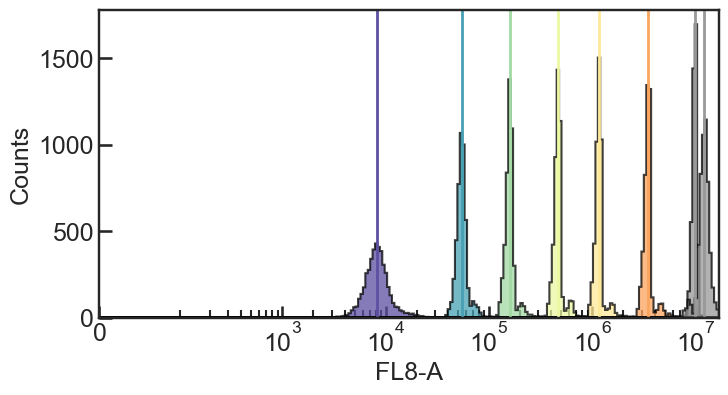

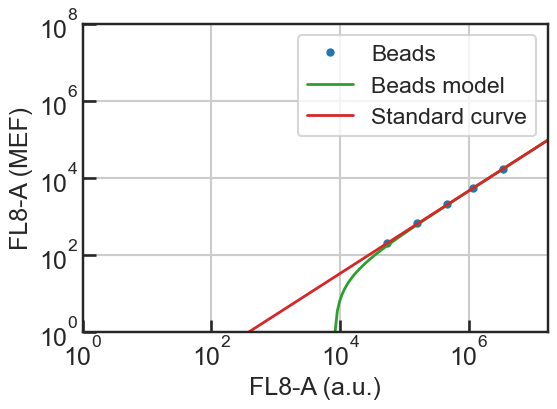

In [15]:
# import FCS data

fileprefix = '../20241205/'

fileext = '.fcs'

m9beads = FlowCal.io.FCSData(fileprefix + '02-Beads-G1' + fileext)

# gate on FSC-A and SSC-A
m9beads_gated = m9beads[(m9beads[:,1] > 1e5) &
                    (m9beads[:,1] < 5e5) &
                    (m9beads[:,3] > 3e5)]
# beads_gated = beads_gated[(beads_gated[:,1] < 8e5) & (beads_gated[:,3] < 3e6)]

FlowCal.plot.density2d(m9beads_gated,
                      channels=['FSC-A','SSC-A'],
                      mode='scatter')

mefl_vals = np.array([0,771,2106,6262,15183,45292,136258,291042])
# meptr_vals = np.array([0,205,643,2021,5278,17018,62451,198933])

# use this because RFP gain is so high that the brightest bead subpopulations overflow.
meptr_vals_low = np.array([0,205,643,2021,5278,17018,np.nan,np.nan]) 

mef_vals = np.array([mefl_vals, meptr_vals_low])

to_mef_m9 = FlowCal.mef.get_transform_fxn(
    m9beads_gated,
    mef_values = mef_vals,
    mef_channels=['FL5-A','FL8-A'],
    plot=True,
)


### FCS files

In [16]:
fcs_dict = dict()

plates = ['04','05','06','07']
rows6 = ['A','B','C','D','E','F']
rows7 = ['A','B','C','D','E','F','G']
grnas6 = ['g1','g2','g3','g4','g5','g6']
grnas7 = ['g8','g9','g10','g11','g12','g13','g14']
cols = [str(i) for i in range(1,13)]

atcs_cl = ['Blank','0','0.02','0.06','0.2','0.43','0.93','2','6','20','60','200']
atcs_m9 = ['Blank','0','0.02','0.2','0.43','0.93','2','3.5','6.3','11.3','20','200']

for plate in plates:
    if (plate=='04') | (plate=='06'):
        rows = rows6
        grnas = grnas6
    else:
        rows = rows7
        grnas = grnas7        
    if (plate=='04') | (plate=='05'):
        media = 'M9'
        media_for_key = 'M9'
        atcs = atcs_m9
    else:
        media = 'CLim'
        media_for_key = 'CL'
        atcs = atcs_cl
        
    prefix = plate+'-'+media+'-'
    for r in range(len(rows)):
        for c in range(len(cols)):
            well = rows[r]+cols[c]
            cond = media_for_key+'_'+grnas[r]+'_'+atcs[c]
            
            fcs_dict[cond] = to_mef_m9(FlowCal.transform.to_rfi(FlowCal.io.FCSData(fileprefix + prefix + well + fileext)), channels=['FL5-A','FL8-A'])

        

### Density gating on FCS data

In [17]:
# This may take a while to run.
frac_to_keep = 0.4

fcs_gated_dict = dict()

for key in fcs_dict.keys():
    fcs = fcs_dict[key]
    
    fcs_gated = FlowCal.gate.density2d(fcs,
                                       channels=['FSC-A','SSC-A'],
                                       gate_fraction=frac_to_keep,
                                      )
    fcs_gated_dict[key] = fcs_gated

### Pickle the gated outputs

In [18]:
# pickle the resulting dictionary

with open('./pickles/241205_fcs_gated_dict.pkl', 'wb') as f:  # open a text file
    pickle.dump(fcs_gated_dict, f) # serialize the list
f.close()

## Replicate 3

### Beads

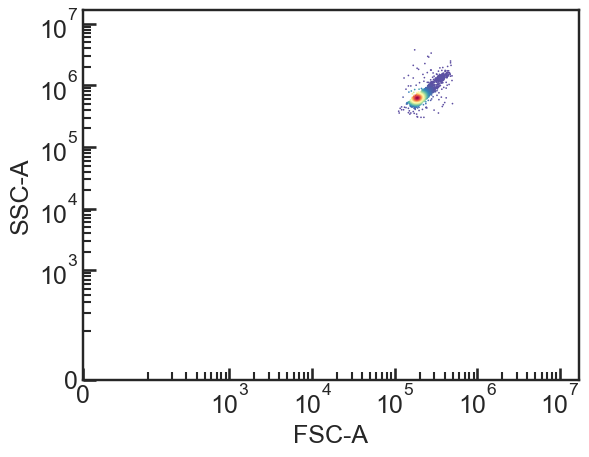

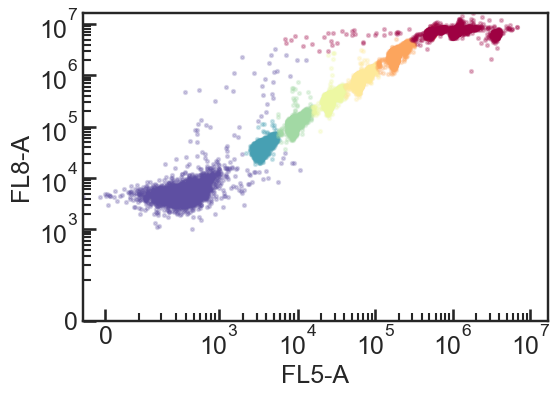

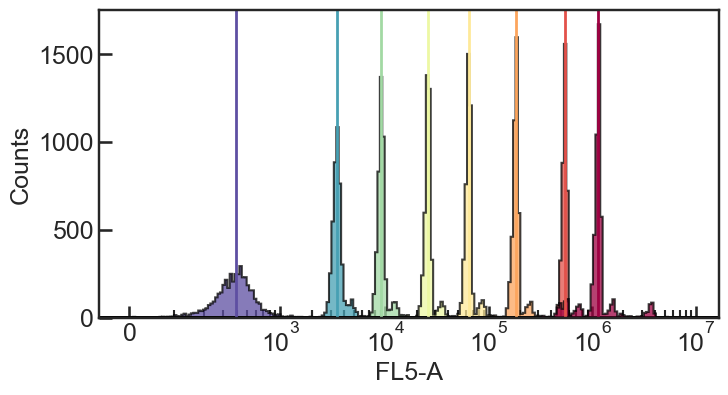

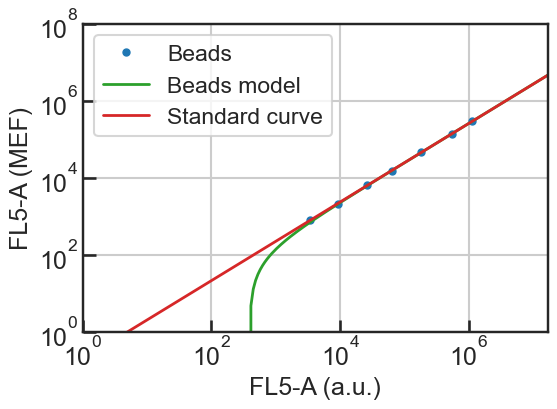

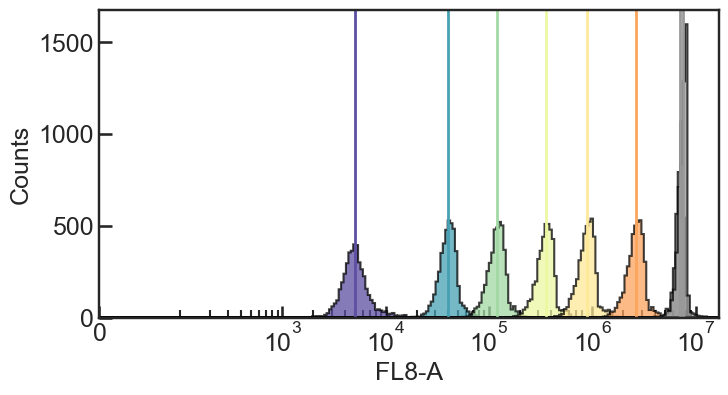

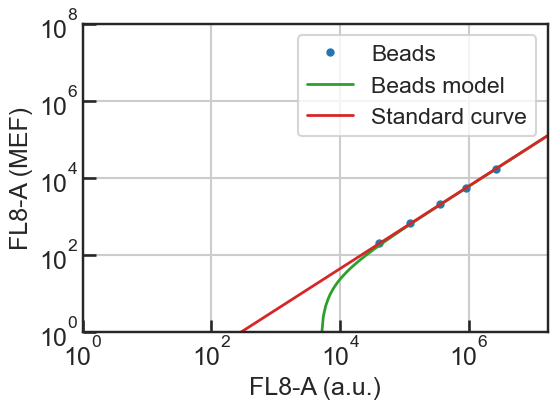

In [19]:
# import FCS data

fileprefix = '../20241208/'

fileext = '.fcs'

m9beads = FlowCal.io.FCSData(fileprefix + '02-Beads-H11' + fileext)

# gate on FSC-A and SSC-A
m9beads_gated = m9beads[(m9beads[:,1] > 1e5) &
                    (m9beads[:,1] < 5e5) &
                    (m9beads[:,3] > 3e5)]
# beads_gated = beads_gated[(beads_gated[:,1] < 8e5) & (beads_gated[:,3] < 3e6)]

FlowCal.plot.density2d(m9beads_gated,
                      channels=['FSC-A','SSC-A'],
                      mode='scatter')

mefl_vals = np.array([0,771,2106,6262,15183,45292,136258,291042])
# meptr_vals = np.array([0,205,643,2021,5278,17018,62451,198933])

# use this because RFP gain is so high that the brightest bead subpopulations overflow.
meptr_vals_low = np.array([0,205,643,2021,5278,17018,np.nan,np.nan]) 

mef_vals = np.array([mefl_vals, meptr_vals_low])

to_mef_m9 = FlowCal.mef.get_transform_fxn(
    m9beads_gated,
    mef_values = mef_vals,
    mef_channels=['FL5-A','FL8-A'],
    plot=True,
)


### FCS files

In [20]:
fcs_dict = dict()

plates = ['04','05','06','07']
rows6 = ['A','B','C','D','E','F']
rows7 = ['A','B','C','D','E','F','G']
grnas6 = ['g1','g2','g3','g4','g5','g6']
grnas7 = ['g8','g9','g10','g11','g12','g13','g14']
cols = [str(i) for i in range(1,13)]

atcs_cl = ['Blank','0','0.02','0.06','0.2','0.43','0.93','2','6','20','60','200']
atcs_m9 = ['Blank','0','0.2','0.43','0.93','2','2.6','3.5','6.3','11.3','20','200']

for plate in plates:
    if (plate=='04') | (plate=='06'):
        rows = rows6
        grnas = grnas6
    else:
        rows = rows7
        grnas = grnas7        
    if (plate=='04') | (plate=='05'):
        media = 'M9'
        media_for_key = 'M9'
        atcs = atcs_m9
    else:
        media = 'CLim'
        media_for_key = 'CL'
        atcs = atcs_cl
        
    prefix = plate+'-'+media+'-'
    for r in range(len(rows)):
        for c in range(len(cols)):
            well = rows[r]+cols[c]
            cond = media_for_key+'_'+grnas[r]+'_'+atcs[c]
            
            fcs_dict[cond] = to_mef_m9(FlowCal.transform.to_rfi(FlowCal.io.FCSData(fileprefix + prefix + well + fileext)), channels=['FL5-A','FL8-A'])

        

### Density gating on FCS data

In [21]:
# This may take a while to run.
frac_to_keep = 0.4

fcs_gated_dict = dict()

for key in fcs_dict.keys():
    fcs = fcs_dict[key]
    
    fcs_gated = FlowCal.gate.density2d(fcs,
                                       channels=['FSC-A','SSC-A'],
                                       gate_fraction=frac_to_keep,
                                      )
    fcs_gated_dict[key] = fcs_gated

### Pickle the gated outputs

In [22]:
# pickle the resulting dictionary

with open('./pickles/241208_fcs_gated_dict.pkl', 'wb') as f:  # open a text file
    pickle.dump(fcs_gated_dict, f) # serialize the list
f.close()

# F and P gates

## Replicate 1

### Beads

In [23]:
# import FCS data

fileprefix = '../20250501/'

fileext = '.fcs'

m9beads = FlowCal.io.FCSData(fileprefix + '07-Beads-H12' + fileext)

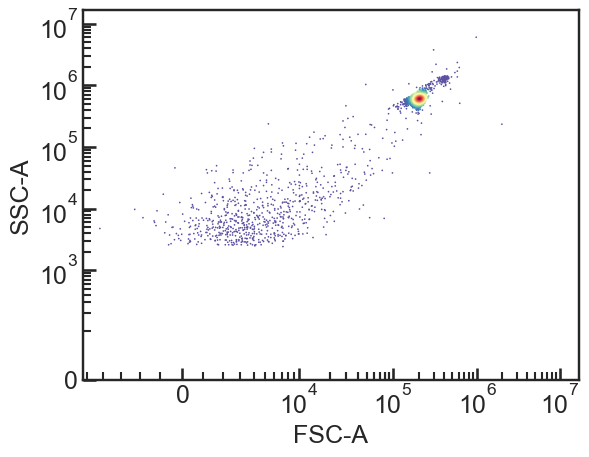

In [24]:
# Plot out beads to get cutoff thresholds
FlowCal.plot.density2d(m9beads,
                      channels=['FSC-A','SSC-A'],
                      mode='scatter')


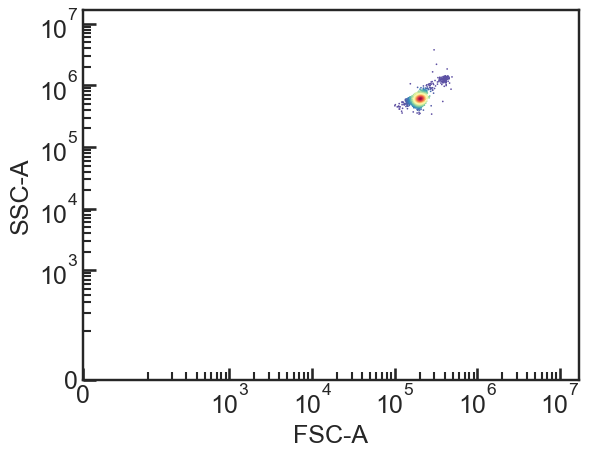

In [25]:
# gate on FSC-A and SSC-A
m9beads_gated = m9beads[(m9beads[:,1] > 1e5) &
                    (m9beads[:,1] < 5e5) &
                    (m9beads[:,3] > 3e5)]

FlowCal.plot.density2d(m9beads_gated,
                      channels=['FSC-A','SSC-A'],
                      mode='scatter')


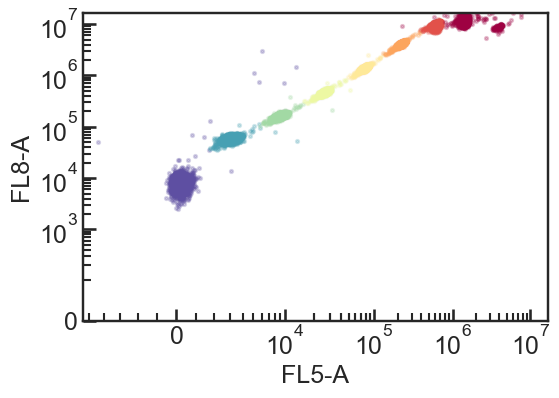

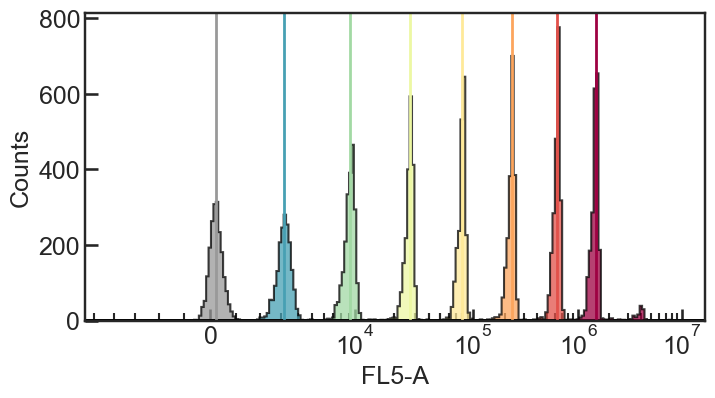

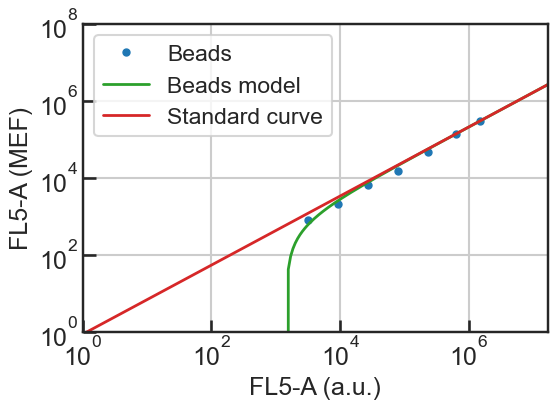

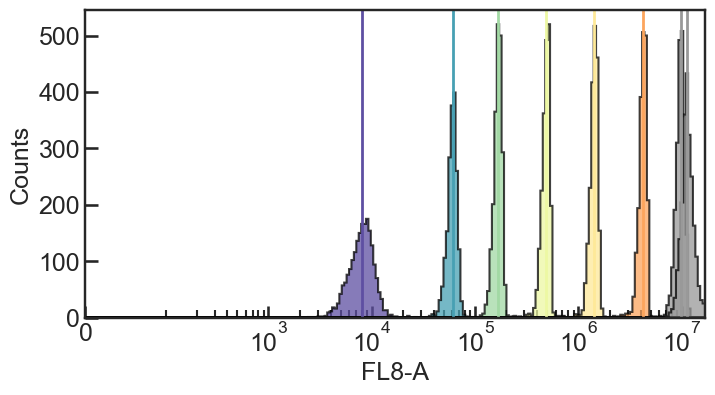

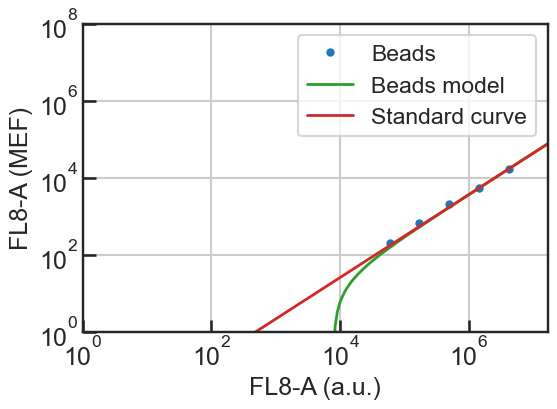

In [26]:
mefl_vals = np.array([0,771,2106,6262,15183,45292,136258,291042])
# meptr_vals = np.array([0,205,643,2021,5278,17018,62451,198933])

# use this array instead because RFP gain is so high that the brightest bead subpopulations overflow.
meptr_vals_low = np.array([0,205,643,2021,5278,17018,np.nan,np.nan]) 

mef_vals = np.array([mefl_vals, meptr_vals_low])

to_mef_m9 = FlowCal.mef.get_transform_fxn(
    m9beads_gated,
    mef_values = mef_vals,
    mef_channels=['FL5-A','FL8-A'],
    plot=True,
)


### FCS files

In [27]:
fcs_dict = dict()

plates = ['06','09','10','11']
medias = ['M9_P','M9_D','CL_P','Well']

rows = ['A','B','C','D','E','F']

grnas = ['g1','g2','g3','g5','g16','g17']
cols = [str(i) for i in range(1,13)]

atcs_cl = ['Blank','0','0.02','0.06','0.2','0.43','0.93','2','6','20','60','200']
atcs_m9 = ['Blank','0','0.2','0.43','0.93','2','2.6','3.5','6.3','11.3','20','100']

for p in range(len(plates)):
    plate = plates[p]
    media = medias[p]

    if (plate=='06')|(plate=='09'):
        atcs = atcs_m9
    else:
        atcs = atcs_cl

    prefix = plate+'-'+media+'-'
    for r in range(len(rows)):
        for c in range(len(cols)):
            well = rows[r]+cols[c]
            if media=='Well':
                media = 'CL_D'
            cond = media+'_'+grnas[r]+'_'+atcs[c]
            
            fcs_dict[cond] = to_mef_m9(FlowCal.transform.to_rfi(FlowCal.io.FCSData(fileprefix + prefix + well + fileext)), channels=['FL5-A','FL8-A'])


### Density gating on FCS data

In [28]:
# density gating

# This may take a while to run.
frac_to_keep = 0.4

fcs_gated_dict = dict()

for key in fcs_dict.keys():
    fcs = fcs_dict[key]
    
    fcs_gated = FlowCal.gate.density2d(fcs,
                                       channels=['FSC-A','SSC-A'],
                                       gate_fraction=frac_to_keep,
                                      )
    fcs_gated_dict[key] = fcs_gated

### Pickle the gated outputs

In [29]:
# pickle the resulting dictionary

with open('./pickles/250501_fcs_gated_dict.pkl', 'wb') as f:  # open a text file
    pickle.dump(fcs_gated_dict, f) # serialize the list
f.close()

## Replicate 2

### Beads

In [30]:
# import FCS data

fileprefix = '../20250509/'

fileext = '.fcs'

m9beads = FlowCal.io.FCSData(fileprefix + '06-Beads-H12' + fileext)

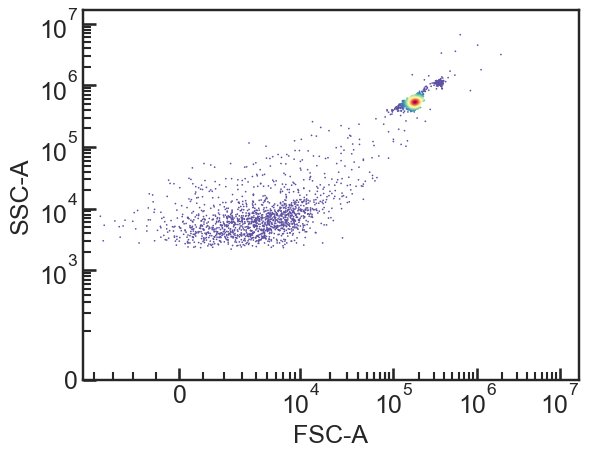

In [31]:
# Plot out beads to get cutoff thresholds
FlowCal.plot.density2d(m9beads,
                      channels=['FSC-A','SSC-A'],
                      mode='scatter')


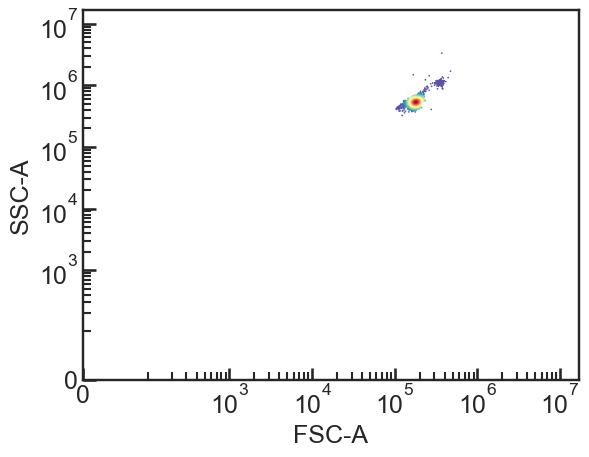

In [32]:
# gate on FSC-A and SSC-A
m9beads_gated = m9beads[(m9beads[:,1] > 1e5) &
                    (m9beads[:,1] < 5e5) &
                    (m9beads[:,3] > 3e5)]
# beads_gated = beads_gated[(beads_gated[:,1] < 8e5) & (beads_gated[:,3] < 3e6)]

FlowCal.plot.density2d(m9beads_gated,
                      channels=['FSC-A','SSC-A'],
                      mode='scatter')


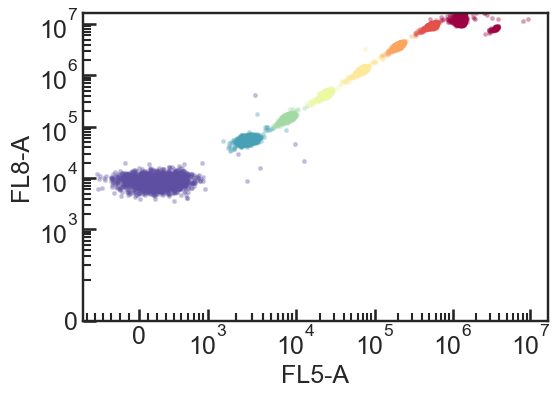

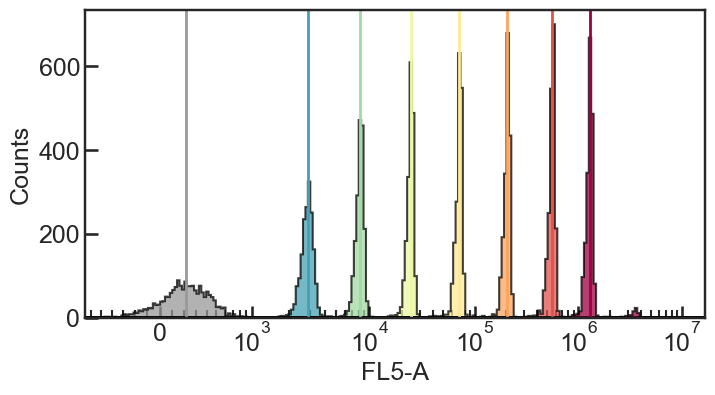

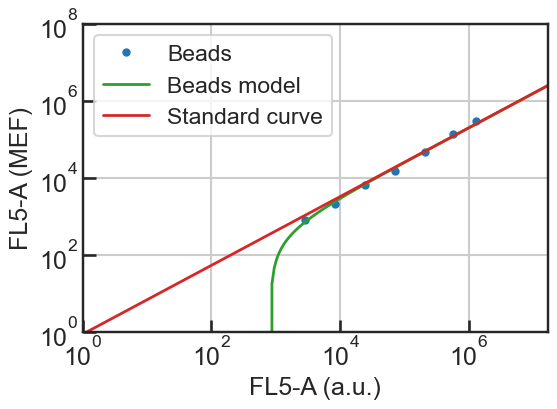

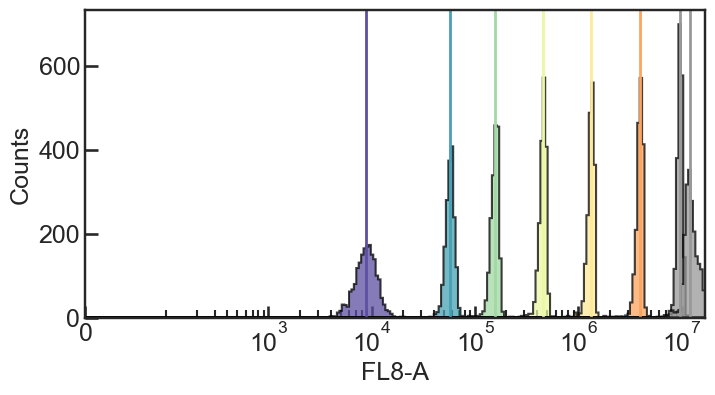

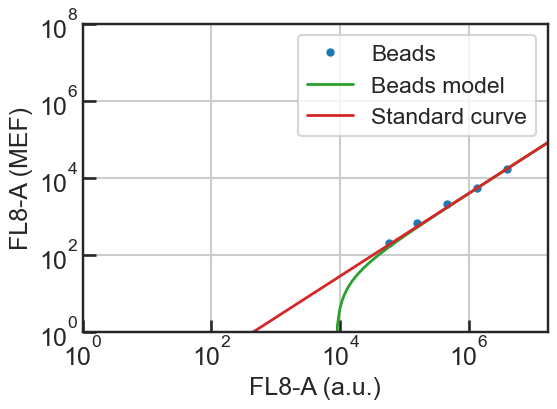

In [33]:
mefl_vals = np.array([0,771,2106,6262,15183,45292,136258,291042])
# meptr_vals = np.array([0,205,643,2021,5278,17018,62451,198933])

# use this because RFP gain is so high that the brightest bead subpopulations overflow.
meptr_vals_low = np.array([0,205,643,2021,5278,17018,np.nan,np.nan]) 

mef_vals = np.array([mefl_vals, meptr_vals_low])

to_mef_m9 = FlowCal.mef.get_transform_fxn(
    m9beads_gated,
    mef_values = mef_vals,
    mef_channels=['FL5-A','FL8-A'],
    plot=True,
)


### FCS files

In [34]:
fcs_dict = dict()

plates = ['08','09','10','11']
medias = ['M9_P','M9_D','CL_P','CL_D']

rows = ['A','B','C','D','E','F']

grnas = ['g1','g2','g3','g5','g16','g17']
cols = [str(i) for i in range(1,13)]

atcs_cl = ['Blank','0','0.02','0.06','0.2','0.43','0.93','2','6','20','60','200']
atcs_m9 = ['Blank','0','0.2','0.43','0.93','2','2.6','3.5','6.3','11.3','20','100']

for p in range(len(plates)):
    plate = plates[p]
    media = medias[p]

    if (plate=='08')|(plate=='09'):
        atcs = atcs_m9
    else:
        atcs = atcs_cl

    prefix = plate+'-'+media+'-'
    for r in range(len(rows)):
        for c in range(len(cols)):
            well = rows[r]+cols[c]
            # if media=='Well':
            #     media = 'CL_D'
            cond = media+'_'+grnas[r]+'_'+atcs[c]
            
            fcs_dict[cond] = to_mef_m9(FlowCal.transform.to_rfi(FlowCal.io.FCSData(fileprefix + prefix + well + fileext)), channels=['FL5-A','FL8-A'])


### Density gating on FCS data

In [35]:
# density gating

# This may take a while to run.
frac_to_keep = 0.4

fcs_gated_dict = dict()

for key in fcs_dict.keys():
    fcs = fcs_dict[key]
    
    fcs_gated = FlowCal.gate.density2d(fcs,
                                       channels=['FSC-A','SSC-A'],
                                       gate_fraction=frac_to_keep,
                                      )
    fcs_gated_dict[key] = fcs_gated

### Pickle the gated outputs

In [36]:
# pickle the resulting dictionary

with open('./pickles/250509_fcs_gated_dict.pkl', 'wb') as f:  # open a text file
    pickle.dump(fcs_gated_dict, f) # serialize the list
f.close()

## Replicate 3

### Beads

In [37]:
# import FCS data

fileprefix = '../20250511/'

fileext = '.fcs'

m9beads = FlowCal.io.FCSData(fileprefix + '07-Beads-H12' + fileext)

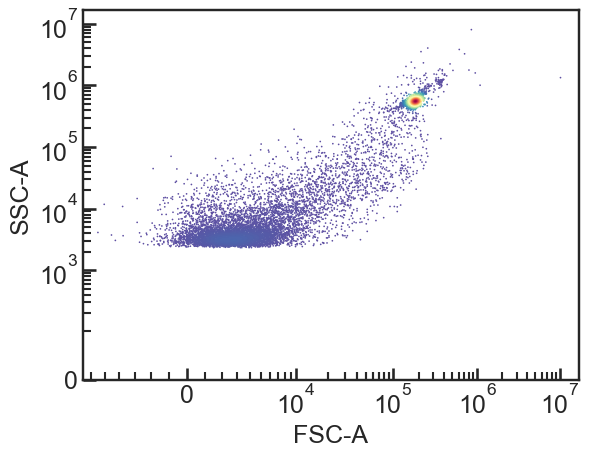

In [38]:
# Plot out beads to get cutoff thresholds
FlowCal.plot.density2d(m9beads,
                      channels=['FSC-A','SSC-A'],
                      mode='scatter')


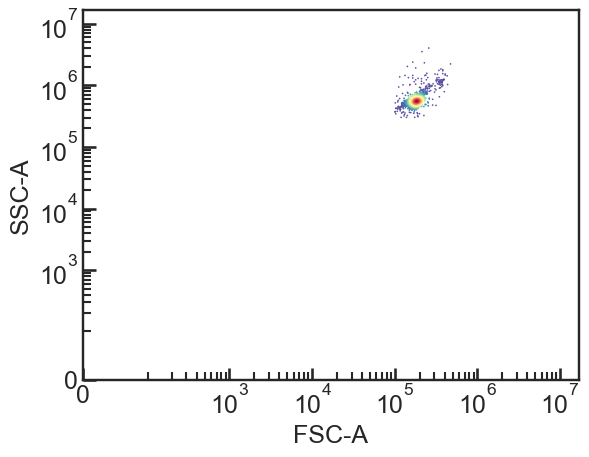

In [39]:
# gate on FSC-A and SSC-A
m9beads_gated = m9beads[(m9beads[:,1] > 1e5) &
                    (m9beads[:,1] < 5e5) &
                    (m9beads[:,3] > 3e5)]

FlowCal.plot.density2d(m9beads_gated,
                      channels=['FSC-A','SSC-A'],
                      mode='scatter')


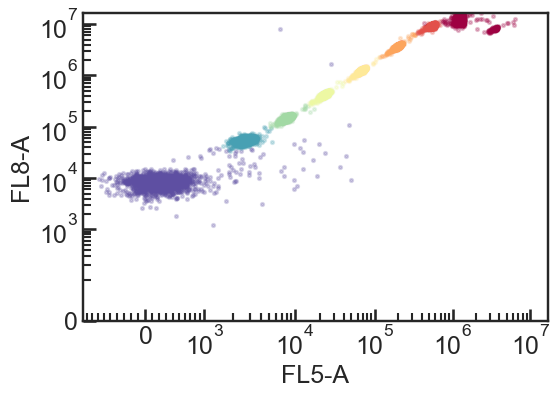

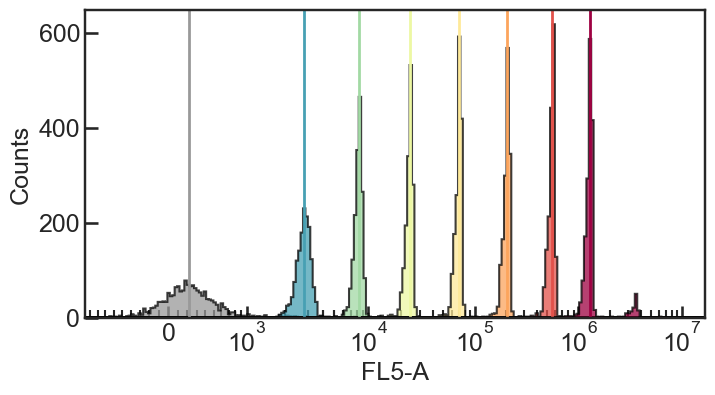

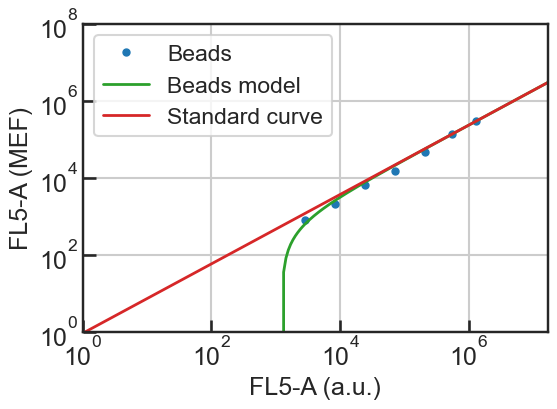

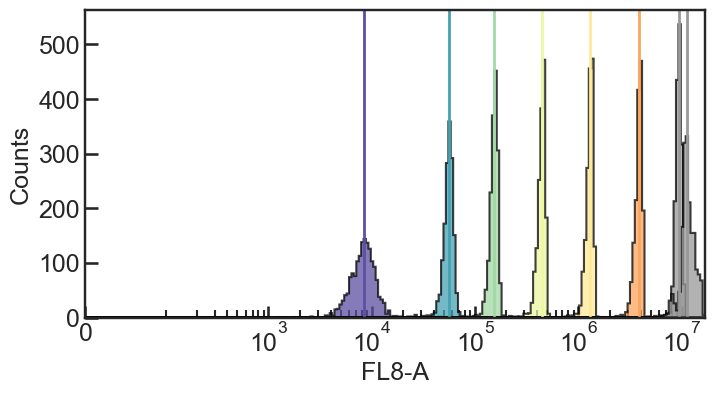

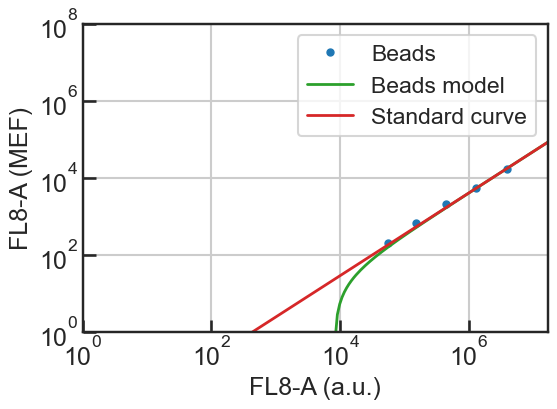

In [40]:
mefl_vals = np.array([0,771,2106,6262,15183,45292,136258,291042])
# meptr_vals = np.array([0,205,643,2021,5278,17018,62451,198933])

# use this because RFP gain is so high that the brightest bead subpopulations overflow.
meptr_vals_low = np.array([0,205,643,2021,5278,17018,np.nan,np.nan]) 

mef_vals = np.array([mefl_vals, meptr_vals_low])

to_mef_m9 = FlowCal.mef.get_transform_fxn(
    m9beads_gated,
    mef_values = mef_vals,
    mef_channels=['FL5-A','FL8-A'],
    plot=True,
)


### FCS files

In [41]:
fcs_dict = dict()

plates = ['08','09','10','11']
medias = ['Well','M9_D','CL_P','CL_D']

rows = ['A','B','C','D','E','F']

grnas = ['g1','g2','g3','g5','g16','g17']
cols = [str(i) for i in range(1,13)]

atcs_cl = ['Blank','0','0.02','0.06','0.2','0.43','0.93','2','6','20','60','200']
atcs_m9 = ['Blank','0','0.2','0.43','0.93','2','2.6','3.5','6.3','11.3','20','100']

for p in range(len(plates)):
    plate = plates[p]
    media = medias[p]

    if (plate=='08')|(plate=='09'):
        atcs = atcs_m9
    else:
        atcs = atcs_cl

    prefix = plate+'-'+media+'-'
    for r in range(len(rows)):
        for c in range(len(cols)):
            well = rows[r]+cols[c]
            if media=='Well':
                media = 'M9_P'
            cond = media+'_'+grnas[r]+'_'+atcs[c]
            
            fcs_dict[cond] = to_mef_m9(FlowCal.transform.to_rfi(FlowCal.io.FCSData(fileprefix + prefix + well + fileext)), channels=['FL5-A','FL8-A'])


### Density gating on FCS data

In [42]:
# density gating

# This may take a while to run.
frac_to_keep = 0.4

fcs_gated_dict = dict()

for key in fcs_dict.keys():
    fcs = fcs_dict[key]
    
    fcs_gated = FlowCal.gate.density2d(fcs,
                                       channels=['FSC-A','SSC-A'],
                                       gate_fraction=frac_to_keep,
                                      )
    fcs_gated_dict[key] = fcs_gated

### Pickle the gated outputs

In [43]:
# pickle the resulting dictionary

with open('./pickles/250511_fcs_gated_dict.pkl', 'wb') as f:  # open a text file
    pickle.dump(fcs_gated_dict, f) # serialize the list
f.close()